In [1]:
import pandas as pd

In [5]:
import zipfile

with zipfile.ZipFile("IMDB Dataset.csv.zip", "r") as zip_ref:
    zip_ref.extractall(".")

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [6]:
import os

print(os.listdir())

['.ipynb_checkpoints', 'IMDB Dataset.csv', 'IMDB Dataset.csv.zip', 'NLP_Sentiment_Analysis.ipynb']


In [7]:
import pandas as pd

df = pd.read_csv("IMDB Dataset.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (50000, 2)


In [8]:
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [9]:
print("Dataset shape:", df.shape)

Dataset shape: (50000, 2)


In [10]:
print("Columns:")
print(df.columns)

Columns:
Index(['review', 'sentiment'], dtype='object')


In [11]:
print("Sentiment distribution:")
print(df['sentiment'].value_counts())

Sentiment distribution:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64


In [12]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
review       0
sentiment    0
dtype: int64


In [13]:
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [14]:

import pandas as pd
import re
import string
import nltk
import matplotlib.pyplot as plt

# Load the zipped dataset
df = pd.read_csv("IMDB Dataset.csv.zip")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())

# Display first 5 rows
df.head()


Dataset loaded successfully!
Dataset shape: (50000, 2)

Column names: ['review', 'sentiment']


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [15]:

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

print("NLTK resources downloaded successfully!")


[nltk_data] Downloading package punkt to C:\Users\Tushar
[nltk_data]     goyal\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to C:\Users\Tushar
[nltk_data]     goyal\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to C:\Users\Tushar
[nltk_data]     goyal\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to C:\Users\Tushar
[nltk_data]     goyal\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to C:\Users\Tushar
[nltk_data]     goyal\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to C:\Users\Tushar
[nltk_data]     goyal\AppData\Roaming\nltk_data...


NLTK resources downloaded successfully!


[nltk_data]   Package omw-1.4 is already up-to-date!


In [16]:

def clean_text(text):
    # Remove HTML tags
    text = re.sub(r'<[^>]+>', '', str(text))

    # Remove URLs
    text = re.sub(r'http\S+|www\S+', '', text)

    # Remove numbers, punctuation, and special characters
    text = re.sub(r'[^a-zA-Z\s]', '', text)

    # Convert to lowercase and remove extra spaces
    text = text.lower().strip()
    text = re.sub(r'\s+', ' ', text)

    return text


sample = 'The movie was AMAZING!!! Best film of 2024. Visit www.movies.com'

print("Original:", sample)
print("Cleaned :", clean_text(sample))


Original: The movie was AMAZING!!! Best film of 2024. Visit www.movies.com
Cleaned : the movie was amazing best film of visit


In [17]:

from nltk.tokenize import word_tokenize

text = "the movie was amazing best film"

tokens = word_tokenize(text)

print("Tokens:", tokens)
print("Token count:", len(tokens))
print("Simple split:", text.split())


Tokens: ['the', 'movie', 'was', 'amazing', 'best', 'film']
Token count: 6
Simple split: ['the', 'movie', 'was', 'amazing', 'best', 'film']


In [18]:

from nltk.corpus import stopwords

stop_words = set(stopwords.words('english'))

# Preserve important negation words for sentiment analysis
stop_words.difference_update({'not', 'no', 'nor'})

def remove_stopwords(tokens):
    return [
        token for token in tokens
        if token not in stop_words and len(token) > 2
    ]

tokens = ['the', 'movie', 'was', 'amazing', 'best', 'film']

filtered = remove_stopwords(tokens)

print("Before removal:", tokens)
print("After removal :", filtered)


Before removal: ['the', 'movie', 'was', 'amazing', 'best', 'film']
After removal : ['movie', 'amazing', 'best', 'film']


In [19]:

from nltk.stem import PorterStemmer, WordNetLemmatizer

stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

words = ['running', 'happily', 'better', 'studies', 'caring', 'wolves']

print(f"{'Word':<15} {'Stemmed':<15} {'Lemmatized':<15}")
print("-" * 45)

for word in words:
    stemmed = stemmer.stem(word)
    lemmatized = lemmatizer.lemmatize(word)

    print(f"{word:<15} {stemmed:<15} {lemmatized:<15}")


Word            Stemmed         Lemmatized     
---------------------------------------------
running         run             running        
happily         happili         happily        
better          better          better         
studies         studi           study          
caring          care            caring         
wolves          wolv            wolf           


In [20]:

def preprocess_text(text):
    # 1. Clean the text
    text = clean_text(text)

    # 2. Tokenize
    tokens = word_tokenize(text)

    # 3. Remove stopwords and short words
    tokens = remove_stopwords(tokens)

    # 4. Lemmatize
    tokens = [lemmatizer.lemmatize(token) for token in tokens]

    # 5. Join tokens into a sentence
    return ' '.join(tokens)


# Apply preprocessing to every review
df['cleaned_review'] = df['review'].apply(preprocess_text)

# Compare original and cleaned reviews
for i in range(3):
    print("Original:", df['review'].iloc[i][:200])
    print("Cleaned :", df['cleaned_review'].iloc[i][:200])
    print()


Original: One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me abo
Cleaned : one reviewer mentioned watching episode youll hooked right exactly happened methe first thing struck brutality unflinching scene violence set right word trust not show faint hearted timid show pull pu

Original: A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece
Cleaned : wonderful little production filming technique unassuming oldtimebbc fashion give comforting sometimes discomforting sense realism entire piece actor extremely well chosen michael sheen not got polari 

Original: I thought this was a wonderful way to spend time on a too hot summer weekend, sitting in the air conditioned theater and watching a light-hearte

In [21]:

from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=1,
    max_df=0.95
)

X = vectorizer.fit_transform(df['cleaned_review'])

print("TF-IDF matrix shape:", X.shape)
print("Vocabulary size:", len(vectorizer.vocabulary_))
print("Sample features:", list(vectorizer.vocabulary_.keys())[:10])


TF-IDF matrix shape: (50000, 5000)
Vocabulary size: 5000
Sample features: ['one', 'reviewer', 'mentioned', 'watching', 'episode', 'youll', 'hooked', 'right', 'exactly', 'happened']


In [22]:

from collections import Counter

def get_top_words(df_subset, n=15):
    all_words = ' '.join(df_subset['cleaned_review']).split()
    return Counter(all_words).most_common(n)


pos_words = get_top_words(
    df[df['sentiment'].str.lower() == 'positive']
)

neg_words = get_top_words(
    df[df['sentiment'].str.lower() == 'negative']
)

print("Top positive words:", pos_words)
print("Top negative words:", neg_words)


Top positive words: [('film', 47894), ('movie', 43133), ('not', 28793), ('one', 26958), ('like', 17541), ('time', 15197), ('good', 14419), ('story', 13648), ('character', 13630), ('great', 12694), ('see', 12532), ('get', 11096), ('well', 11079), ('make', 10988), ('really', 10676)]
Top negative words: [('movie', 55892), ('film', 41915), ('not', 32812), ('one', 25719), ('like', 22249), ('even', 14921), ('time', 14199), ('good', 14196), ('bad', 14095), ('character', 13943), ('would', 13633), ('get', 13339), ('make', 12576), ('really', 12224), ('scene', 11013)]


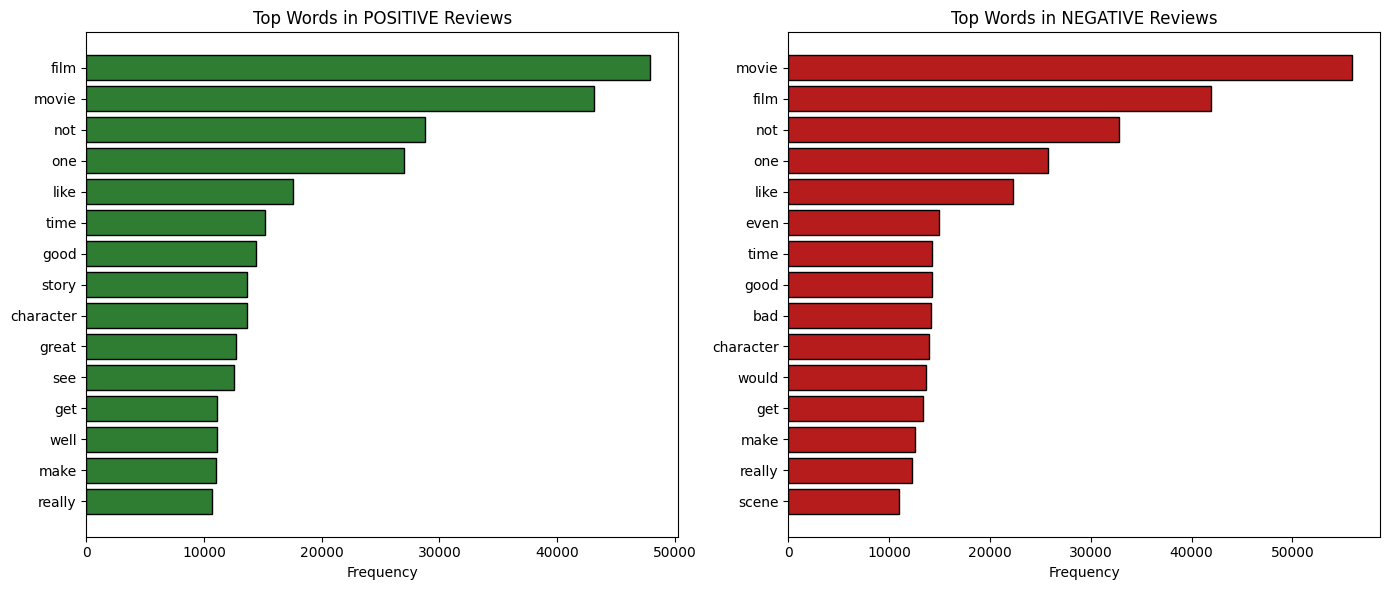

Chart saved as top_words_by_sentiment.png


In [26]:

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, words, title, color in [
    (axes[0], pos_words, 'Top Words in POSITIVE Reviews', '#2E7D32'),
    (axes[1], neg_words, 'Top Words in NEGATIVE Reviews', '#B71C1C')
]:
    ws = [w[0] for w in words]
    cs = [w[1] for w in words]

    ax.barh(ws[::-1], cs[::-1], color=color, edgecolor='black')
    ax.set_title(title)
    ax.set_xlabel('Frequency')

plt.tight_layout()
plt.savefig('top_words_by_sentiment.png', dpi=150, bbox_inches='tight')
plt.show()

print("Chart saved as top_words_by_sentiment.png")


In [27]:

df.to_csv('IMDB_Preprocessed.csv', index=False)

print("Preprocessed dataset saved successfully!")
print("Total reviews:", len(df))
print("Columns:", df.columns.tolist())


Preprocessed dataset saved successfully!
Total reviews: 50000
Columns: ['review', 'sentiment', 'cleaned_review']


In [28]:

# Check the original and cleaned reviews
df[['review', 'cleaned_review', 'sentiment']].head(5)


,review,cleaned_review,sentiment
0,One of the other reviewers has mentioned that ...,one reviewer mentioned watching episode youll ...,positive
1,A wonderful little production. <br /><br />The...,wonderful little production filming technique ...,positive
2,I thought this was a wonderful way to spend ti...,thought wonderful way spend time hot summer we...,positive
3,Basically there's a family where a little boy ...,basically there family little boy jake think t...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",petter matteis love time money visually stunni...,positive


In [29]:

print("Missing values before processing:")
print(df[['review', 'sentiment']].isnull().sum())

print("\nMissing values in cleaned reviews:")
print(df['cleaned_review'].isnull().sum())


Missing values before processing:
review       0
sentiment    0
dtype: int64

Missing values in cleaned reviews:
0


In [30]:

import os

print("Files in your project folder:")
for file in os.listdir():
    print(file)


Files in your project folder:
.ipynb_checkpoints
IMDB Dataset.csv
IMDB Dataset.csv.zip
IMDB_Preprocessed.csv
NLP_Sentiment_Analysis.ipynb
top_words_by_sentiment.png


In [31]:

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns

print("Machine learning libraries imported successfully!")


Machine learning libraries imported successfully!


In [32]:

# Input features and target labels
y = df['sentiment'].str.lower()

print("Feature matrix shape:", X.shape)
print("\nSentiment distribution:")
print(y.value_counts())


Feature matrix shape: (50000, 5000)

Sentiment distribution:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64


In [33]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 40000
Testing samples: 10000


In [34]:

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

print("Model training completed successfully!")


Model training completed successfully!


In [35]:

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Model Accuracy: 89.33%

Classification Report:
              precision    recall  f1-score   support

    negative       0.90      0.89      0.89      5000
    positive       0.89      0.90      0.89      5000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



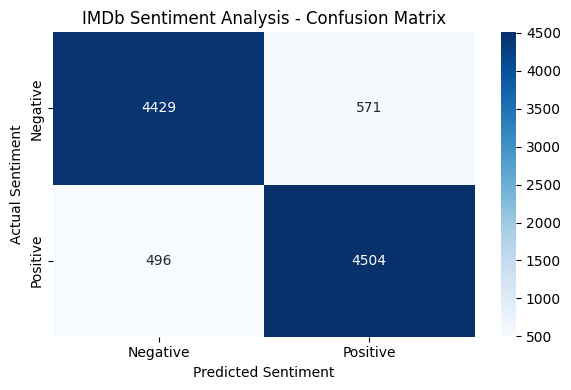

In [36]:

cm = confusion_matrix(
    y_test, y_pred,
    labels=['negative', 'positive']
)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive']
)

plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')
plt.title('IMDb Sentiment Analysis - Confusion Matrix')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150)
plt.show()


In [42]:

from sklearn.model_selection import train_test_split

# Encode positive = 1 and negative = 0
df['label'] = (df['sentiment'].str.lower() == 'positive').astype(int)

print("Label distribution:")
print(df['label'].value_counts())

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    df['cleaned_review'].fillna(''),
    df['label'],
    test_size=0.25,
    random_state=42,
    stratify=df['label']
)

print("\nTraining size:", len(X_train))
print("Testing size:", len(X_test))


Label distribution:
label
1    25000
0    25000
Name: count, dtype: int64

Training size: 37500
Testing size: 12500


In [44]:

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

sentiment_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features=10000,
        ngram_range=(1, 2),
        min_df=1,
        sublinear_tf=True
    )),
    ('clf', LogisticRegression(
        max_iter=500,
        C=1.0,
        random_state=42
    ))
])

sentiment_pipeline.fit(X_train, y_train)

y_pred = sentiment_pipeline.predict(X_test)

print("Sentiment model trained successfully!")
print("Predictions made on", len(y_pred), "test reviews")


Sentiment model trained successfully!
Predictions made on 12500 test reviews


Test Accuracy: 89.83%

Classification Report:
              precision    recall  f1-score   support

    Negative       0.91      0.89      0.90      6250
    Positive       0.89      0.91      0.90      6250

    accuracy                           0.90     12500
   macro avg       0.90      0.90      0.90     12500
weighted avg       0.90      0.90      0.90     12500

ROC-AUC Score: 0.9633


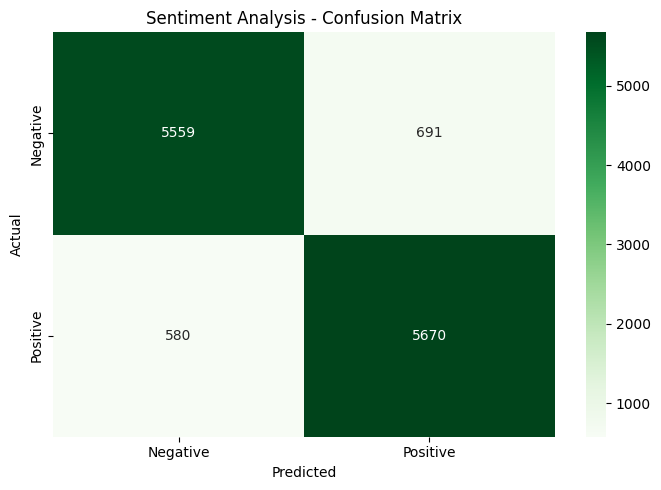

Confusion matrix saved!


In [45]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)
import seaborn as sns
import matplotlib.pyplot as plt

accuracy = accuracy_score(y_test, y_pred)
print(f"Test Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=['Negative', 'Positive'],
    zero_division=0
))

y_proba = sentiment_pipeline.predict_proba(X_test)[:, 1]
auc = roc_auc_score(y_test, y_proba)
print(f"ROC-AUC Score: {auc:.4f}")

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive'],
    ax=ax
)

ax.set_title('Sentiment Analysis - Confusion Matrix')
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')

plt.tight_layout()
plt.savefig('sentiment_confusion_matrix.png', dpi=150)
plt.show()

print("Confusion matrix saved!")


In [46]:

def predict_sentiment(review_text):
    probabilities = sentiment_pipeline.predict_proba([review_text])[0]
    prediction = sentiment_pipeline.predict([review_text])[0]

    label = 'POSITIVE' if prediction == 1 else 'NEGATIVE'
    confidence = max(probabilities) * 100

    print("Review:", review_text)
    print("Prediction:", label)
    print(f"Confidence: {confidence:.1f}%")
    print(
        f"Positive: {probabilities[1]*100:.1f}% | "
        f"Negative: {probabilities[0]*100:.1f}%"
    )
    print("-" * 60)


new_reviews = [
    "This film was absolutely incredible. The acting was excellent!",
    "Complete disaster. The story was terrible and boring.",
    "Not bad, some good moments but overall quite mediocre.",
    "The visual effects were stunning and the story was captivating.",
    "I cannot believe how boring this was. Totally disappointed."
]

for review in new_reviews:
    predict_sentiment(review)


Review: This film was absolutely incredible. The acting was excellent!
Prediction: POSITIVE
Confidence: 98.6%
Positive: 98.6% | Negative: 1.4%
------------------------------------------------------------
Review: Complete disaster. The story was terrible and boring.
Prediction: NEGATIVE
Confidence: 99.8%
Positive: 0.2% | Negative: 99.8%
------------------------------------------------------------
Review: Not bad, some good moments but overall quite mediocre.
Prediction: NEGATIVE
Confidence: 85.3%
Positive: 14.7% | Negative: 85.3%
------------------------------------------------------------
Review: The visual effects were stunning and the story was captivating.
Prediction: POSITIVE
Confidence: 86.3%
Positive: 86.3% | Negative: 13.7%
------------------------------------------------------------
Review: I cannot believe how boring this was. Totally disappointed.
Prediction: NEGATIVE
Confidence: 99.6%
Positive: 0.4% | Negative: 99.6%
----------------------------------------------------------

In [47]:

%pip install wordcloud


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


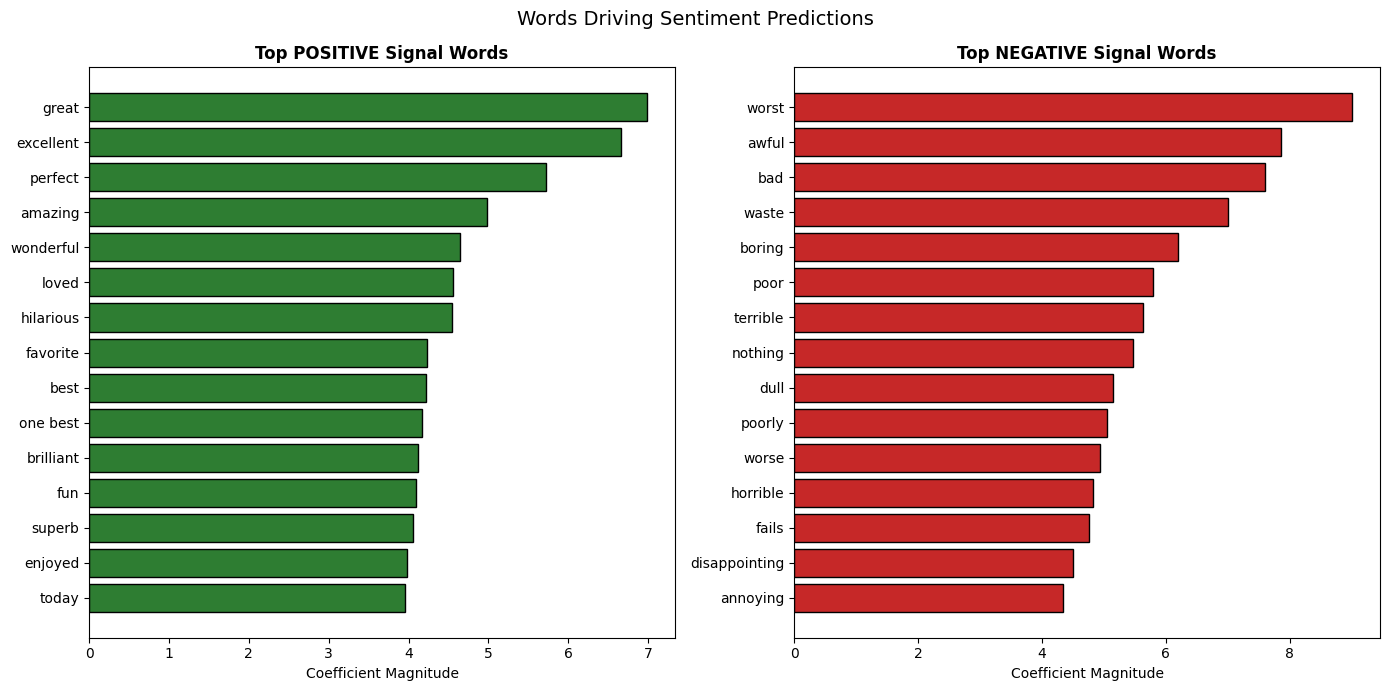

Saved: feature_importance_nlp.png


In [48]:

import numpy as np
import matplotlib.pyplot as plt

# Extract TF-IDF and Logistic Regression components
tfidf = sentiment_pipeline.named_steps['tfidf']
clf = sentiment_pipeline.named_steps['clf']

# Get word features and their coefficients
coefficients = clf.coef_[0]
feature_names = tfidf.get_feature_names_out()

top_n = 15

# Highest coefficients indicate positive sentiment
pos_idx = np.argsort(coefficients)[-top_n:][::-1]

# Lowest coefficients indicate negative sentiment
neg_idx = np.argsort(coefficients)[:top_n]

pos_words = [(feature_names[i], coefficients[i]) for i in pos_idx]
neg_words = [(feature_names[i], coefficients[i]) for i in neg_idx]

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

for ax, words, title, color in [
    (axes[0], pos_words, 'Top POSITIVE Signal Words', '#2E7D32'),
    (axes[1], neg_words, 'Top NEGATIVE Signal Words', '#C62828')
]:
    ws = [w[0] for w in words]
    cs = [abs(w[1]) for w in words]

    ax.barh(ws[::-1], cs[::-1], color=color, edgecolor='black')
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Coefficient Magnitude')

plt.suptitle('Words Driving Sentiment Predictions', fontsize=14)
plt.tight_layout()
plt.savefig('feature_importance_nlp.png', dpi=150, bbox_inches='tight')
plt.show()

print("Saved: feature_importance_nlp.png")


In [ ]:

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
import matplotlib.pyplot as plt
import numpy as np

# Define the three classifiers
models = {
    'Logistic Regression': LogisticRegression(
        max_iter=300, random_state=42
    ),
    'Naive Bayes': MultinomialNB(alpha=0.1),
    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

results = {}

# Run 5-fold cross-validation
for name, classifier in models.items():
    pipe = Pipeline([
        ('tfidf', TfidfVectorizer(
            max_features=5000,
            ngram_range=(1, 2)
        )),
        ('clf', classifier)
    ])

    scores = cross_val_score(
        pipe,
        df['cleaned_review'].fillna(''),
        df['label'],
        cv=5,
        scoring='accuracy',
        n_jobs=-1
    )

    results[name] = scores
    print(
        f'{name}: mean={scores.mean():.3f}, '
        f'std={scores.std():.3f}'
    )

# Plot model comparison
names = list(results.keys())
means = [results[n].mean() for n in names]
stds = [results[n].std() for n in names]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    names,
    means,
    yerr=stds,
    edgecolor='black',
    capsize=7
)

for bar, mean in zip(bars, means):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.005,
        f'{mean:.3f}',
        ha='center',
        fontsize=10
    )

ax.set_ylim(0.5, 1.1)
ax.set_title('Classifier Comparison - NLP Sentiment Analysis')
ax.set_ylabel('Cross-Validation Accuracy')
plt.xticks(rotation=10)
plt.tight_layout()

plt.savefig('nlp_model_comparison.png', dpi=150)
plt.show()

print("Saved: nlp_model_comparison.png")


In [ ]:

import joblib
import os

# Save the complete pipeline
joblib.dump(sentiment_pipeline, 'sentiment_model.pkl')

print("Model saved successfully!")

# Load the saved model
loaded_model = joblib.load('sentiment_model.pkl')

# Test the loaded model
test_review = [
    "This was an absolutely wonderful and magical experience!"
]

result = loaded_model.predict(test_review)

print(
    "Loaded model prediction:",
    "POSITIVE" if result[0] == 1 else "NEGATIVE"
)

size_kb = os.path.getsize('sentiment_model.pkl') / 1024
print(f"Model file size: {size_kb:.1f} KB")


In [ ]:

import os

required_files = [
    'top_words_by_sentiment.png',
    'sentiment_confusion_matrix.png',
    'wordcloud_positive.png',
    'wordcloud_negative.png',
    'feature_importance_nlp.png',
    'nlp_model_comparison.png',
    'sentiment_model.pkl'
]

print("Task 2 submission checklist:\n")

for filename in required_files:
    status = "READY" if os.path.exists(filename) else "MISSING"
    print(f"[{status}] {filename}")


# Project 3 – NLP and Sentiment Analysis

## 1. Introduction

Natural Language Processing (NLP) is a branch of Artificial Intelligence that enables computers to understand, process, and analyze human language. Sentiment analysis is an NLP technique used to identify whether a piece of text expresses a positive or negative opinion. In this project, the IMDb movie review dataset is used to build a machine learning model that classifies movie reviews as positive or negative.

## 2. Dataset and Text Preprocessing

The IMDb dataset contains movie reviews and their sentiment labels. Before training the model, the review text is cleaned by removing HTML tags, URLs, unnecessary punctuation, and numbers. The text is converted to lowercase, tokenized, and lemmatized. Common stopwords are removed while important negation words, such as “not” and “no,” are preserved because they can change a review’s meaning.

## 3. TF-IDF Technique

TF-IDF stands for Term Frequency–Inverse Document Frequency. It converts text into numerical features that machine learning algorithms can understand. Term Frequency (TF) measures how often a word appears in a document. Inverse Document Frequency (IDF) reduces the importance of words that occur in many documents. Therefore, TF-IDF gives greater importance to words that are useful for distinguishing one document from another.

In this project, TF-IDF uses unigrams and bigrams, allowing the model to consider individual words and two-word combinations. Logistic Regression is trained using these features to predict the sentiment of movie reviews. Model performance is evaluated using accuracy, precision, recall, F1-score, ROC-AUC, and a confusion matrix. Other algorithms, including Multinomial Naive Bayes and Random Forest, are compared using cross-validation.

## 4. Real-World Applications

**Application 1: Customer Feedback Analysis**  
Businesses can analyze customer reviews, feedback forms, and survey responses to understand customer satisfaction. Sentiment analysis helps identify complaints, improve products, and make better business decisions.

**Application 2: Social Media Monitoring**  
Organizations can analyze posts and comments on social media platforms to understand public opinions about their products, services, or campaigns. This helps them respond to negative feedback and identify positive customer reactions.

## 5. Conclusion

This project demonstrates how NLP preprocessing, TF-IDF feature extraction, and machine learning can be combined to classify text sentiment. Comparing different models and evaluating their performance helps identify a suitable approach for sentiment classification. The same techniques can be adapted to many applications involving reviews, feedback, and opinions.